# Installs

In [2]:
%pip install xgboost -v
%pip install matplotlib seaborn
%pip install scikit-learn
%pip install pandas
%pip install numpy
%pip install --upgrade scipy
%pip install optuna

Using pip 25.1 from /Users/jptillman/miniconda3/lib/python3.13/site-packages/pip (python 3.13)
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Imports

In [3]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier, plot_importance
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

/Users/jptillman/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Visualization Helpers

In [18]:
def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'],
                yticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'])
    plt.title(title)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

def plot_roc_curve(y_true, y_prob, title='ROC Curve'):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC Curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# Experiment 1 — Minimum 1 Fight Experience

Includes fights where **both fighters have at least 1 prior UFC fight**.

## Load Data

In [19]:
TRAIN_PATH_EXP1 = '../data/processed/fights_training_exp1.csv'
VAL_PATH_EXP1   = '../data/processed/fights_validation_exp1.csv'
TEST_PATH_EXP1  = '../data/processed/fights_testing_exp1.csv'

train1 = pd.read_csv(TRAIN_PATH_EXP1)
val1   = pd.read_csv(VAL_PATH_EXP1)
test1  = pd.read_csv(TEST_PATH_EXP1)

columns_to_drop = ['winner', 'is_mirror', 'fight_id']

X_train1 = train1.drop(columns=columns_to_drop)
y_train1  = train1['winner']

X_val1 = val1.drop(columns=columns_to_drop)
y_val1  = val1['winner']

X_test1 = test1.drop(columns=columns_to_drop)
y_test1  = test1['winner']

print(f"Exp1 Training Data: {X_train1.shape[0]} fights, {X_train1.shape[1]} features")
print(f"Exp1 Validation Data: {X_val1.shape[0]} fights")
print(f"Exp1 Testing Data: {X_test1.shape[0]} fights")

Exp1 Training Data: 6644 fights, 63 features
Exp1 Validation Data: 950 fights
Exp1 Testing Data: 1900 fights


## Hyperparameter Optimization
I couldn't get the optimized parameters to beat baseline

In [5]:
def objective_exp1(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 20
    }
    model = XGBClassifier(**param)
    model.fit(X_train1, y_train1, eval_set=[(X_val1, y_val1)], verbose=False)
    preds = model.predict(X_val1)
    return accuracy_score(y_val1, preds)

print("Starting Optuna optimization for Exp1...")
study_exp1 = optuna.create_study(direction='maximize')
study_exp1.enqueue_trial({
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 5,
    'subsample': 0.65,
    'colsample_bytree': 0.65
})
study_exp1.optimize(objective_exp1, n_trials=100)

print("\nBest hyperparameters (Exp1):", study_exp1.best_params)
print(f"Best Validation Accuracy (Exp1): {study_exp1.best_value:.2%}")

[I 2026-04-24 11:20:48,249] A new study created in memory with name: no-name-6d747b14-a1f0-4ef6-ac48-bb16d432cbd2


Starting Optuna optimization for Exp1...


[I 2026-04-24 11:20:48,625] Trial 0 finished with value: 0.6136842105263158 and parameters: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.65, 'colsample_bytree': 0.65}. Best is trial 0 with value: 0.6136842105263158.
[I 2026-04-24 11:20:49,023] Trial 1 finished with value: 0.6168421052631579 and parameters: {'n_estimators': 758, 'learning_rate': 0.11448879957640694, 'max_depth': 7, 'subsample': 0.5104155983069582, 'colsample_bytree': 0.8355730672724848}. Best is trial 1 with value: 0.6168421052631579.
[I 2026-04-24 11:20:49,936] Trial 2 finished with value: 0.6178947368421053 and parameters: {'n_estimators': 590, 'learning_rate': 0.09902967389282463, 'max_depth': 9, 'subsample': 0.8107028045157052, 'colsample_bytree': 0.9470047061572092}. Best is trial 2 with value: 0.6178947368421053.
[I 2026-04-24 11:20:50,763] Trial 3 finished with value: 0.6294736842105263 and parameters: {'n_estimators': 763, 'learning_rate': 0.012486292299345883, 'max_depth': 3, 'sub


Best hyperparameters (Exp1): {'n_estimators': 197, 'learning_rate': 0.1614408164381142, 'max_depth': 6, 'subsample': 0.5428508577979201, 'colsample_bytree': 0.5835971727877708}
Best Validation Accuracy (Exp1): 64.95%


## XGB Parameters
Will have to tune these to produce the best results

In [20]:
xgb_model_exp1 = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.649,
    colsample_bytree=0.649,
    random_state=42,
    early_stopping_rounds=20
)

## Training

In [21]:
xgb_model_exp1.fit(
    X_train1, y_train1,
    eval_set=[(X_train1, y_train1), (X_val1, y_val1)],
    verbose=25
)
print("\nExp1 Training Complete!")

[0]	validation_0-logloss:0.68826	validation_1-logloss:0.69083
[25]	validation_0-logloss:0.61670	validation_1-logloss:0.65624
[50]	validation_0-logloss:0.58157	validation_1-logloss:0.65003
[75]	validation_0-logloss:0.55608	validation_1-logloss:0.64903
[93]	validation_0-logloss:0.54101	validation_1-logloss:0.64888

Exp1 Training Complete!


## Evaluation

EXP1 TEST ACCURACY: 64.89%

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.64      0.65       950
           1       0.65      0.66      0.65       950

    accuracy                           0.65      1900
   macro avg       0.65      0.65      0.65      1900
weighted avg       0.65      0.65      0.65      1900



<Figure size 1000x800 with 0 Axes>

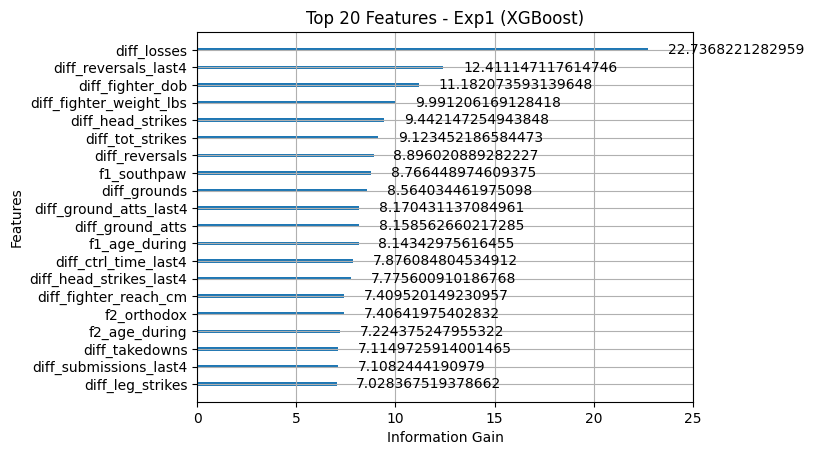

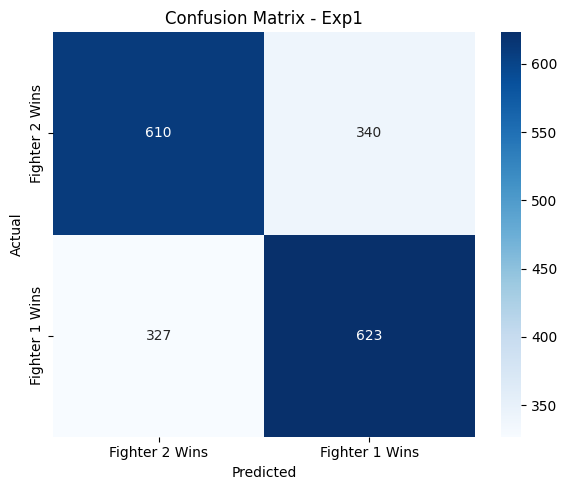

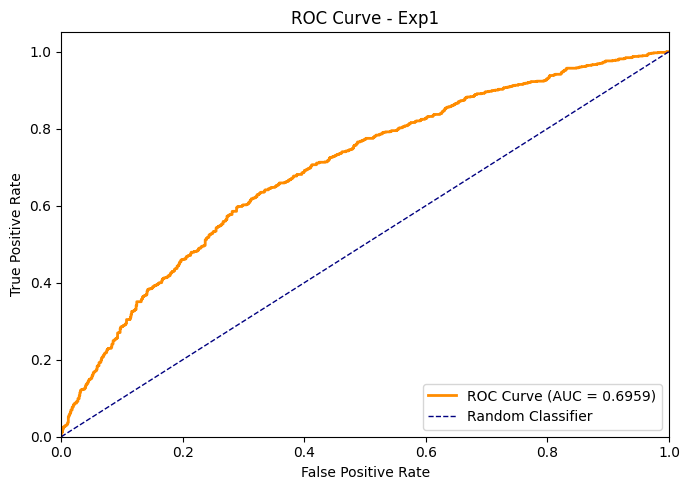

In [22]:
y_pred1      = xgb_model_exp1.predict(X_test1)
y_pred1_prob = xgb_model_exp1.predict_proba(X_test1)[:, 1]

print("=" * 50)
print(f"EXP1 TEST ACCURACY: {accuracy_score(y_test1, y_pred1):.2%}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test1, y_pred1))

# Feature Importance
plt.figure(figsize=(10, 8))
plot_importance(xgb_model_exp1, max_num_features=20, importance_type='gain',
                title='Top 20 Features - Exp1 (XGBoost)', xlabel='Information Gain')
plt.show()

# Confusion Matrix
plot_confusion_matrix(y_test1, y_pred1, title='Confusion Matrix - Exp1')

# ROC Curve
plot_roc_curve(y_test1, y_pred1_prob, title='ROC Curve - Exp1')

# Experiment 2 — Minimum 2 Fights Experience

Includes fights where **both fighters have at least 2 prior UFC fights**.

## Load Data

In [23]:
TRAIN_PATH_EXP2 = '../data/processed/fights_training_exp2.csv'
VAL_PATH_EXP2   = '../data/processed/fights_validation_exp2.csv'
TEST_PATH_EXP2  = '../data/processed/fights_testing_exp2.csv'

train2 = pd.read_csv(TRAIN_PATH_EXP2)
val2   = pd.read_csv(VAL_PATH_EXP2)
test2  = pd.read_csv(TEST_PATH_EXP2)

X_train2 = train2.drop(columns=columns_to_drop)
y_train2  = train2['winner']

X_val2 = val2.drop(columns=columns_to_drop)
y_val2  = val2['winner']

X_test2 = test2.drop(columns=columns_to_drop)
y_test2  = test2['winner']

print(f"Exp2 Training Data: {X_train2.shape[0]} fights, {X_train2.shape[1]} features")
print(f"Exp2 Validation Data: {X_val2.shape[0]} fights")
print(f"Exp2 Testing Data: {X_test2.shape[0]} fights")

Exp2 Training Data: 5212 fights, 63 features
Exp2 Validation Data: 744 fights
Exp2 Testing Data: 1492 fights


## Hyperparameter Optimization
I couldn't get the optimized parameters to beat baseline

In [10]:
def objective_exp2(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 20
    }
    model = XGBClassifier(**param)
    model.fit(X_train2, y_train2, eval_set=[(X_val2, y_val2)], verbose=False)
    preds = model.predict(X_val2)
    return accuracy_score(y_val2, preds)

print("Starting Optuna optimization for Exp2...")
study_exp2 = optuna.create_study(direction='maximize')
study_exp2.enqueue_trial({
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 5,
    'subsample': 0.65,
    'colsample_bytree': 0.65
})
study_exp2.optimize(objective_exp2, n_trials=100)

print("\nBest hyperparameters (Exp2):", study_exp2.best_params)
print(f"Best Validation Accuracy (Exp2): {study_exp2.best_value:.2%}")

[I 2026-04-24 11:22:16,563] A new study created in memory with name: no-name-480c8f59-1595-4b39-8770-978eefa2f8cf


Starting Optuna optimization for Exp2...


[I 2026-04-24 11:22:17,596] Trial 0 finished with value: 0.6518817204301075 and parameters: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.65, 'colsample_bytree': 0.65}. Best is trial 0 with value: 0.6518817204301075.
[I 2026-04-24 11:22:17,935] Trial 1 finished with value: 0.6559139784946236 and parameters: {'n_estimators': 360, 'learning_rate': 0.11916547384754841, 'max_depth': 5, 'subsample': 0.7984567010748456, 'colsample_bytree': 0.6405803291380276}. Best is trial 1 with value: 0.6559139784946236.
[I 2026-04-24 11:22:19,204] Trial 2 finished with value: 0.6451612903225806 and parameters: {'n_estimators': 728, 'learning_rate': 0.028593222962177457, 'max_depth': 5, 'subsample': 0.7890720251214914, 'colsample_bytree': 0.880042995589531}. Best is trial 1 with value: 0.6559139784946236.
[I 2026-04-24 11:22:19,977] Trial 3 finished with value: 0.6115591397849462 and parameters: {'n_estimators': 630, 'learning_rate': 0.18404930787004342, 'max_depth': 9, 'subs


Best hyperparameters (Exp2): {'n_estimators': 919, 'learning_rate': 0.02781517364895751, 'max_depth': 3, 'subsample': 0.7085720007635778, 'colsample_bytree': 0.9593643201227381}
Best Validation Accuracy (Exp2): 69.35%


## XGB Parameters
Will have to tune these to produce the best results

In [24]:
xgb_model_exp2 = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.649,
    colsample_bytree=0.649,
    random_state=42,
    early_stopping_rounds=20
)

## Training

In [25]:
xgb_model_exp2.fit(
    X_train2, y_train2,
    eval_set=[(X_train2, y_train2), (X_val2, y_val2)],
    verbose=25
)
print("\nExp2 Training Complete!")

[0]	validation_0-logloss:0.68825	validation_1-logloss:0.68967
[25]	validation_0-logloss:0.60746	validation_1-logloss:0.64341
[50]	validation_0-logloss:0.56322	validation_1-logloss:0.63240
[75]	validation_0-logloss:0.53396	validation_1-logloss:0.63014
[100]	validation_0-logloss:0.50850	validation_1-logloss:0.62996
[105]	validation_0-logloss:0.50366	validation_1-logloss:0.62955

Exp2 Training Complete!


## Evaluation

EXP2 TEST ACCURACY: 60.79%

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.61      0.61       746
           1       0.61      0.61      0.61       746

    accuracy                           0.61      1492
   macro avg       0.61      0.61      0.61      1492
weighted avg       0.61      0.61      0.61      1492



<Figure size 1000x800 with 0 Axes>

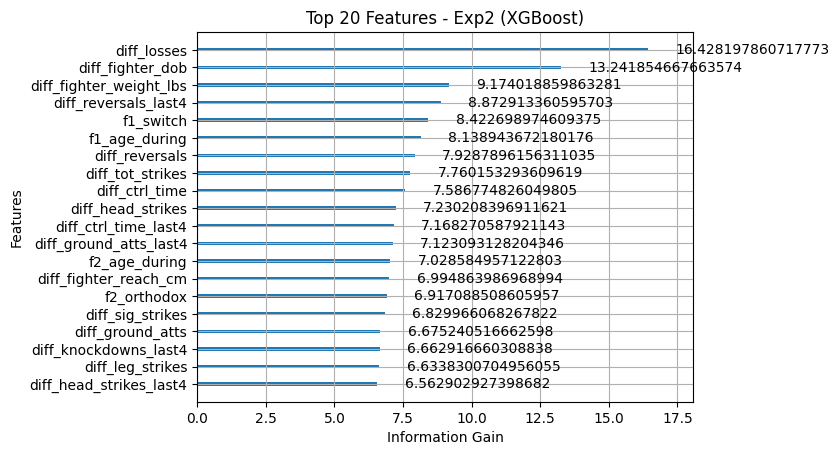

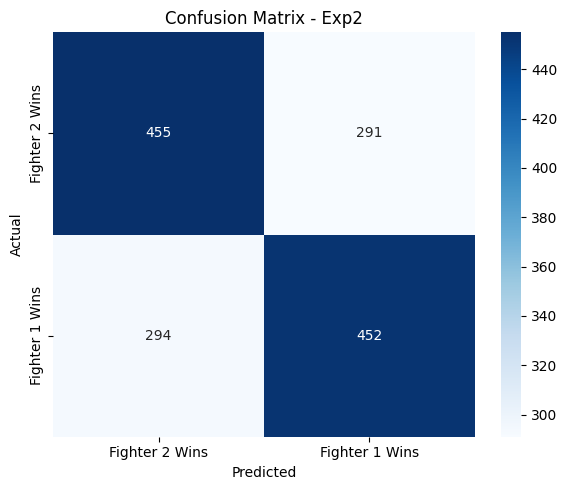

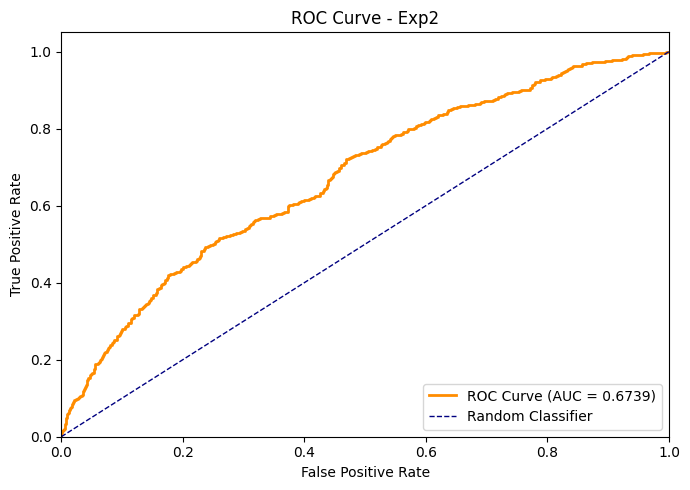

In [26]:
y_pred2      = xgb_model_exp2.predict(X_test2)
y_pred2_prob = xgb_model_exp2.predict_proba(X_test2)[:, 1]

print("=" * 50)
print(f"EXP2 TEST ACCURACY: {accuracy_score(y_test2, y_pred2):.2%}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test2, y_pred2))

# Feature Importance
plt.figure(figsize=(10, 8))
plot_importance(xgb_model_exp2, max_num_features=20, importance_type='gain',
                title='Top 20 Features - Exp2 (XGBoost)', xlabel='Information Gain')
plt.show()

# Confusion Matrix
plot_confusion_matrix(y_test2, y_pred2, title='Confusion Matrix - Exp2')

# ROC Curve
plot_roc_curve(y_test2, y_pred2_prob, title='ROC Curve - Exp2')

In [27]:
# --- Accuracy Summary ---
val1_pred  = xgb_model_exp1.predict(X_val1)
val2_pred  = xgb_model_exp2.predict(X_val2)
test1_pred = xgb_model_exp1.predict(X_test1)
test2_pred = xgb_model_exp2.predict(X_test2)

print("=" * 35)
print(f"{'':>6} {'Val Acc':>10} {'Test Acc':>10}")
print("-" * 35)
print(f"{'Exp1':>6} {accuracy_score(y_val1, val1_pred):>10.2%} {accuracy_score(y_test1, test1_pred):>10.2%}")
print(f"{'Exp2':>6} {accuracy_score(y_val2, val2_pred):>10.2%} {accuracy_score(y_test2, test2_pred):>10.2%}")
print("=" * 35)


          Val Acc   Test Acc
-----------------------------------
  Exp1     61.79%     64.89%
  Exp2     64.52%     60.79%


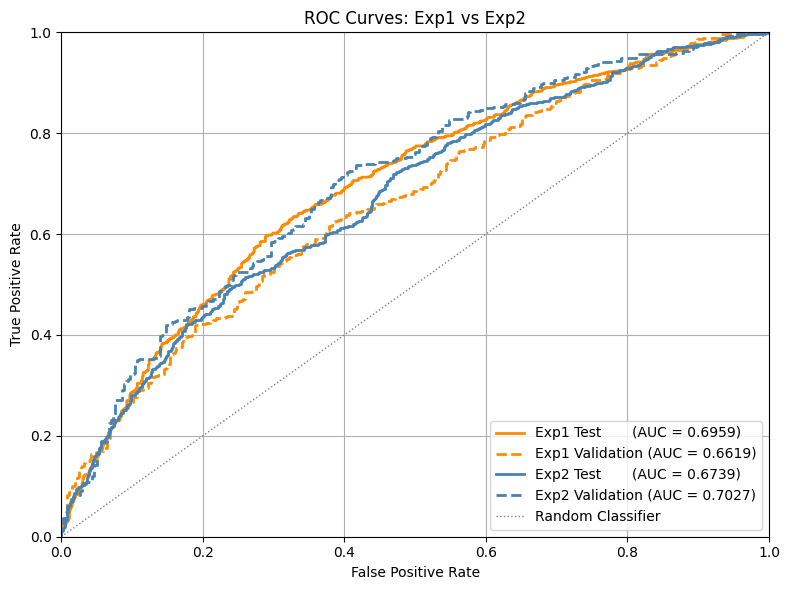

In [28]:
# Combined ROC Curve — Exp1 & Exp2 (Test + Validation)
from sklearn.metrics import roc_curve, auc

y_pred1_prob = xgb_model_exp1.predict_proba(X_test1)[:, 1]
y_val1_prob  = xgb_model_exp1.predict_proba(X_val1)[:, 1]
y_pred2_prob = xgb_model_exp2.predict_proba(X_test2)[:, 1]
y_val2_prob  = xgb_model_exp2.predict_proba(X_val2)[:, 1]

fpr_test1, tpr_test1, _ = roc_curve(y_test1, y_pred1_prob)
fpr_val1,  tpr_val1,  _ = roc_curve(y_val1,  y_val1_prob)
fpr_test2, tpr_test2, _ = roc_curve(y_test2, y_pred2_prob)
fpr_val2,  tpr_val2,  _ = roc_curve(y_val2,  y_val2_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_test1, tpr_test1, color='darkorange', lw=2,                 label=f'Exp1 Test       (AUC = {auc(fpr_test1, tpr_test1):.4f})')
plt.plot(fpr_val1,  tpr_val1,  color='darkorange', lw=2, linestyle='--', label=f'Exp1 Validation (AUC = {auc(fpr_val1,  tpr_val1):.4f})')
plt.plot(fpr_test2, tpr_test2, color='steelblue',  lw=2,                 label=f'Exp2 Test       (AUC = {auc(fpr_test2, tpr_test2):.4f})')
plt.plot(fpr_val2,  tpr_val2,  color='steelblue',  lw=2, linestyle='--', label=f'Exp2 Validation (AUC = {auc(fpr_val2,  tpr_val2):.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Exp1 vs Exp2')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()



In [33]:
TRAIN_PATH = '../data/processed/fights_training.csv'
VAL_PATH   = '../data/processed/fights_validation.csv'
TEST_PATH  = '../data/processed/fights_testing.csv'

train0 = pd.read_csv(TRAIN_PATH)
val0   = pd.read_csv(VAL_PATH)
test0  = pd.read_csv(TEST_PATH)

X_train0 = train0.drop(columns=['winner'])
y_train0  = train0['winner']

X_val0 = val0.drop(columns=['winner'])
y_val0  = val0['winner']

X_test0 = test0.drop(columns=['winner'])
y_test0  = test0['winner']

print(f"General Training Data: {X_train0.shape[0]} fights, {X_train0.shape[1]} features")
print(f"General Validation Data: {X_val0.shape[0]} fights")
print(f"General Testing Data: {X_test0.shape[0]} fights")


General Training Data: 7468 fights, 45 features
General Validation Data: 1066 fights
General Testing Data: 2136 fights


In [29]:
xgb_model_general = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.649,
    colsample_bytree=0.649,
    random_state=42,
    early_stopping_rounds=20
)

xgb_model_general.fit(
    X_train0, y_train0,
    eval_set=[(X_train0, y_train0), (X_val0, y_val0)],
    verbose=25
)
print("\nGeneral Training Complete!")


[0]	validation_0-logloss:0.68825	validation_1-logloss:0.68961
[25]	validation_0-logloss:0.62501	validation_1-logloss:0.66275
[50]	validation_0-logloss:0.59359	validation_1-logloss:0.65584
[75]	validation_0-logloss:0.57072	validation_1-logloss:0.65303
[100]	validation_0-logloss:0.55237	validation_1-logloss:0.65327
[125]	validation_0-logloss:0.53552	validation_1-logloss:0.65355
[136]	validation_0-logloss:0.52809	validation_1-logloss:0.65391

General Training Complete!


GENERAL TEST ACCURACY: 63.90%

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.65      0.64      1068
           1       0.64      0.63      0.64      1068

    accuracy                           0.64      2136
   macro avg       0.64      0.64      0.64      2136
weighted avg       0.64      0.64      0.64      2136



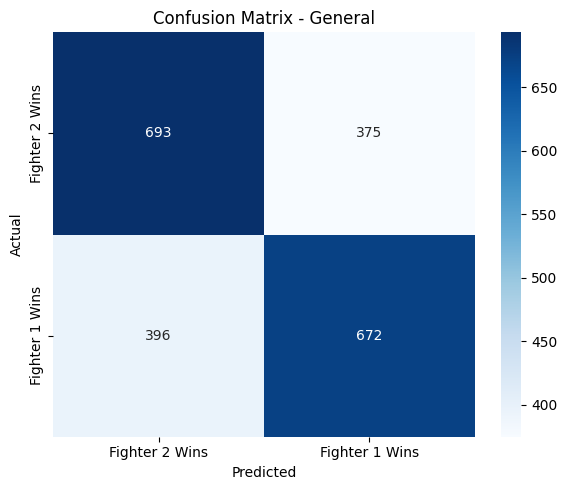

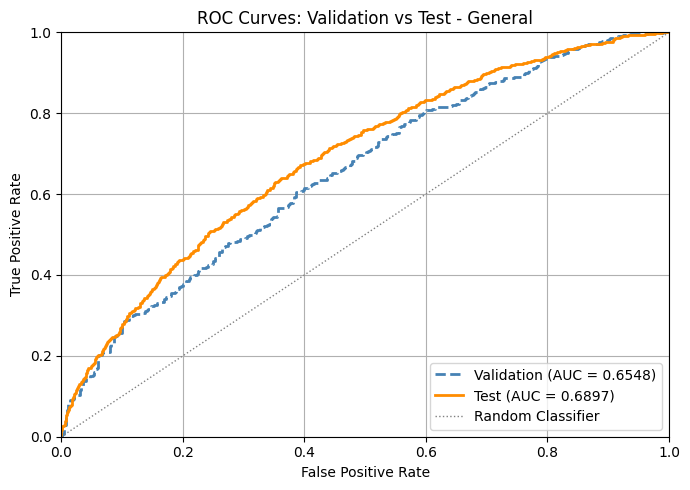

In [30]:
y_pred0      = xgb_model_general.predict(X_test0)
y_pred0_prob = xgb_model_general.predict_proba(X_test0)[:, 1]
y_val0_prob  = xgb_model_general.predict_proba(X_val0)[:, 1]

print("=" * 50)
print(f"GENERAL TEST ACCURACY: {accuracy_score(y_test0, y_pred0):.2%}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test0, y_pred0))

# Confusion Matrix
cm = confusion_matrix(y_test0, y_pred0)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'],
            yticklabels=['Fighter 2 Wins', 'Fighter 1 Wins'])
plt.title('Confusion Matrix - General')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# ROC Curve
fpr_val0,  tpr_val0,  _ = roc_curve(y_val0,  y_val0_prob)
fpr_test0, tpr_test0, _ = roc_curve(y_test0, y_pred0_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr_val0,  tpr_val0,  color='steelblue',  lw=2, linestyle='--', label=f'Validation (AUC = {auc(fpr_val0, tpr_val0):.4f})')
plt.plot(fpr_test0, tpr_test0, color='darkorange',  lw=2,                 label=f'Test (AUC = {auc(fpr_test0, tpr_test0):.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Validation vs Test - General')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:
val0_pred  = xgb_model_general.predict(X_val0)
val1_pred  = xgb_model_exp1.predict(X_val1)
val2_pred  = xgb_model_exp2.predict(X_val2)
test0_pred = xgb_model_general.predict(X_test0)
test1_pred = xgb_model_exp1.predict(X_test1)
test2_pred = xgb_model_exp2.predict(X_test2)

print("=" * 38)
print(f"{'Model':>9} {'Val Acc':>10} {'Test Acc':>10}")
print("-" * 38)
print(f"{'General':>9} {accuracy_score(y_val0, val0_pred):>10.2%} {accuracy_score(y_test0, test0_pred):>10.2%}")
print(f"{'Exp1':>9} {accuracy_score(y_val1, val1_pred):>10.2%} {accuracy_score(y_test1, test1_pred):>10.2%}")
print(f"{'Exp2':>9} {accuracy_score(y_val2, val2_pred):>10.2%} {accuracy_score(y_test2, test2_pred):>10.2%}")
print("=" * 38)


    Model    Val Acc   Test Acc
--------------------------------------
  General     60.51%     63.90%
     Exp1     61.79%     64.89%
     Exp2     64.52%     60.79%


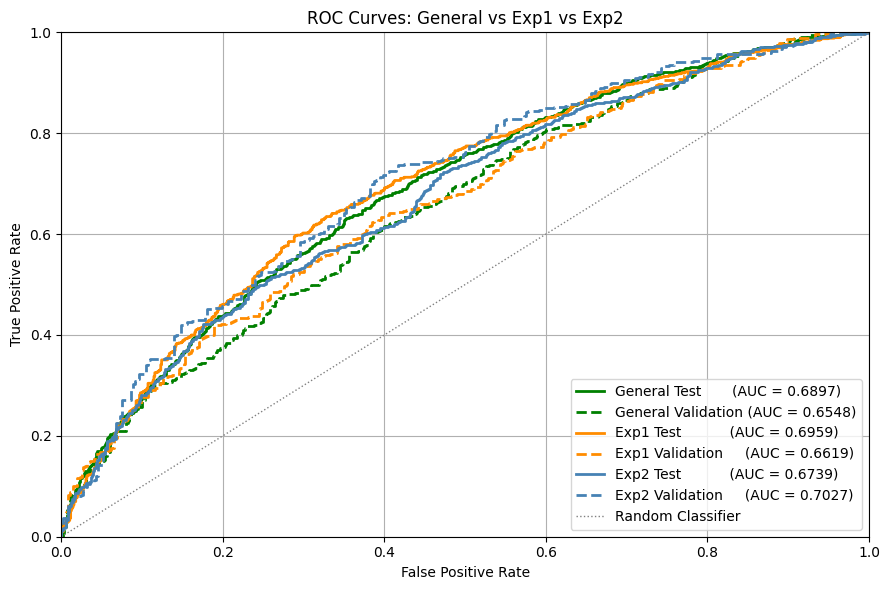

In [34]:
# Combined ROC Curve — General, Exp1 & Exp2 (Test + Validation)
y_pred0_prob = xgb_model_general.predict_proba(X_test0)[:, 1]
y_val0_prob  = xgb_model_general.predict_proba(X_val0)[:, 1]
y_pred1_prob = xgb_model_exp1.predict_proba(X_test1)[:, 1]
y_val1_prob  = xgb_model_exp1.predict_proba(X_val1)[:, 1]
y_pred2_prob = xgb_model_exp2.predict_proba(X_test2)[:, 1]
y_val2_prob  = xgb_model_exp2.predict_proba(X_val2)[:, 1]

fpr_test0, tpr_test0, _ = roc_curve(y_test0, y_pred0_prob)
fpr_val0,  tpr_val0,  _ = roc_curve(y_val0,  y_val0_prob)
fpr_test1, tpr_test1, _ = roc_curve(y_test1, y_pred1_prob)
fpr_val1,  tpr_val1,  _ = roc_curve(y_val1,  y_val1_prob)
fpr_test2, tpr_test2, _ = roc_curve(y_test2, y_pred2_prob)
fpr_val2,  tpr_val2,  _ = roc_curve(y_val2,  y_val2_prob)

plt.figure(figsize=(9, 6))
plt.plot(fpr_test0, tpr_test0, color='green',      lw=2,                 label=f'General Test       (AUC = {auc(fpr_test0, tpr_test0):.4f})')
plt.plot(fpr_val0,  tpr_val0,  color='green',      lw=2, linestyle='--', label=f'General Validation (AUC = {auc(fpr_val0,  tpr_val0):.4f})')
plt.plot(fpr_test1, tpr_test1, color='darkorange', lw=2,                 label=f'Exp1 Test           (AUC = {auc(fpr_test1, tpr_test1):.4f})')
plt.plot(fpr_val1,  tpr_val1,  color='darkorange', lw=2, linestyle='--', label=f'Exp1 Validation     (AUC = {auc(fpr_val1,  tpr_val1):.4f})')
plt.plot(fpr_test2, tpr_test2, color='steelblue',  lw=2,                 label=f'Exp2 Test           (AUC = {auc(fpr_test2, tpr_test2):.4f})')
plt.plot(fpr_val2,  tpr_val2,  color='steelblue',  lw=2, linestyle='--', label=f'Exp2 Validation     (AUC = {auc(fpr_val2,  tpr_val2):.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: General vs Exp1 vs Exp2')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


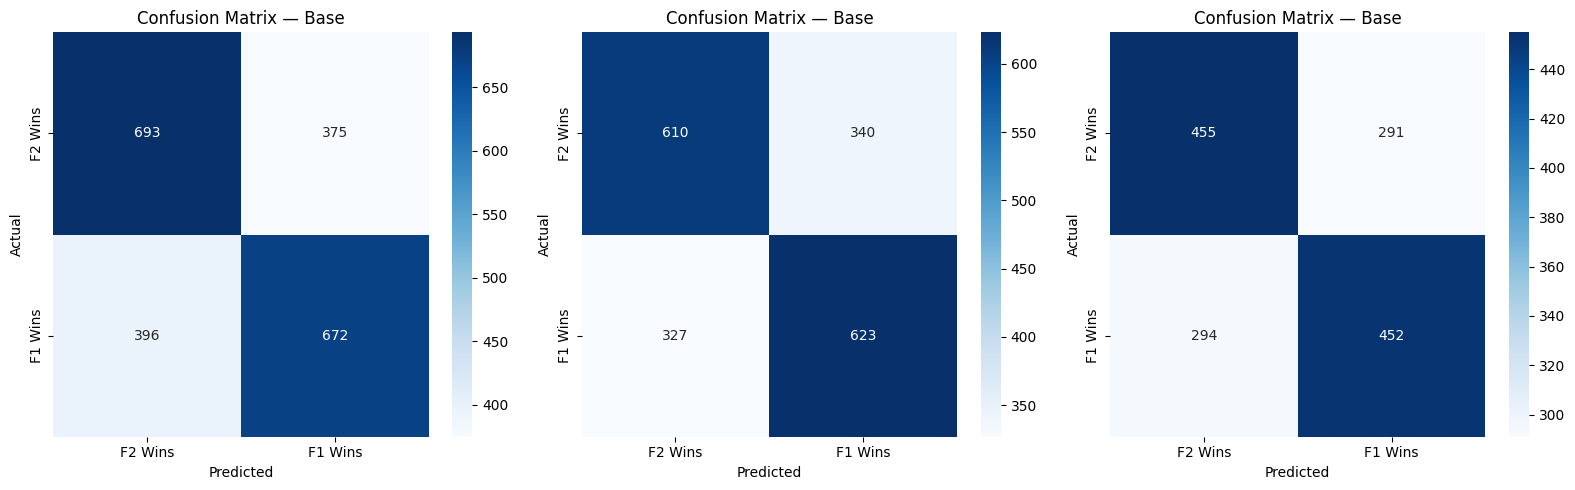

In [36]:
# Combined Confusion Matrices — General, Exp1, Exp2
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model, X_test, y_test, title in [
    (axes[0], xgb_model_general, X_test0, y_test0, 'General'),
    (axes[1], xgb_model_exp1,    X_test1, y_test1, 'Exp1'),
    (axes[2], xgb_model_exp2,    X_test2, y_test2, 'Exp2'),
]:
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['F2 Wins', 'F1 Wins'],
                yticklabels=['F2 Wins', 'F1 Wins'])
    ax.set_title(f'Confusion Matrix — Base')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()
